# 05 · Modelado supervisado

Pronóstico de la demanda horaria del SIN a 24 h, en las dos tablas de modelado:
**r24** (la demanda se conoce hasta `t − 24 h`) y **r120** (hasta `t − 120 h`,
el escenario con el rezago de publicación). Recorre el modelado en el orden en
que se hizo:

1. partición temporal y validación cruzada;
2. baselines;
3. modelos lineales;
4. clasificación de `alerta_pico`;
5. ensembles;
6. búsqueda de hiperparámetros;
7. interpretabilidad;
8. selección del modelo final, el único paso que usa el bloque de prueba.

Todo el cálculo vive en `src/modelado` (probado en `tests/test_modelado_*.py`).
Aquí se llama a esas funciones cuando el cálculo es rápido y se leen los JSON de
`docs/resultados` cuando es largo (las búsquedas tardan unos 30 minutos). Las
reglas del modelado están en `CLAUDE.md`.

In [1]:
import sys, warnings
from pathlib import Path

# Sube desde la carpeta del notebook hasta la raiz del proyecto, la que contiene
# src/ingesta: funciona igual en notebooks/ que en notebooks/limpieza/<dataset>/.
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ingesta").is_dir())
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

DATASETS = RAIZ / "datasets"
print("raiz     :", RAIZ)
print("datasets :", DATASETS, "->", "existe" if DATASETS.exists() else "FALTA")

raiz     : C:\Users\manue\OneDrive\Documentos\PROYECTOS PORTAFOLIO REAL\SIEM EXPLORER
datasets : C:\Users\manue\OneDrive\Documentos\PROYECTOS PORTAFOLIO REAL\SIEM EXPLORER\datasets -> existe


In [2]:
import json
from IPython.display import Image, display

RESULTADOS = RAIZ / "docs" / "resultados"
FIGURAS = RAIZ / "docs" / "figuras" / "modelado"

def resultado(nombre):
    return json.loads((RESULTADOS / nombre).read_text(encoding="utf-8"))

def figura(nombre, ancho=900):
    # La figura del informe, reducida: el notebook no tiene que cargar el PNG a resolucion completa.
    from io import BytesIO
    from PIL import Image as Imagen
    imagen = Imagen.open(FIGURAS / nombre)
    imagen.thumbnail((ancho, ancho * 4))
    destino = BytesIO()
    imagen.convert("RGB").save(destino, format="PNG", optimize=True)
    display(Image(data=destino.getvalue()))

## 1. Datos y partición

La carga comprueba el SHA-256 de cada tabla contra su registro y que la lista de variables salga de la tabla.

In [3]:
from modelado.datos import cargar_tabla
from modelado.particion import particionar, validacion_cruzada

datos, particiones = {}, {}
for clave in ("r24", "r120"):
    (X, y, fechas), registro = cargar_tabla(clave)
    indices, _ = particionar(fechas)
    datos[clave], particiones[clave] = (X, y, fechas), indices
    print(f"{clave}: {X.shape[0]:,} filas x {X.shape[1]} variables -> {list(X.columns)}")

r24: 49,513 filas x 16 variables -> ['lag_24', 'lag_168', 'ma_168', 'std_168', 'temperatura_c', 'hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos', 'mes_sin', 'mes_cos', 'es_festivo', 'es_vispera_festivo', 'es_puente', 'es_semana_santa', 'es_ultima_semana_diciembre']
r120: 49,417 filas x 15 variables -> ['lag_168', 'ma_168', 'std_168', 'temperatura_c', 'hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos', 'mes_sin', 'mes_cos', 'es_festivo', 'es_vispera_festivo', 'es_puente', 'es_semana_santa', 'es_ultima_semana_diciembre']


In [4]:
X, y, fechas = datos["r24"]
indices = particiones["r24"]
pd.DataFrame({bloque: {"filas": len(pos), "desde": fechas.iloc[pos[0]], "hasta": fechas.iloc[pos[-1]]}
              for bloque, pos in indices.items()}).T

,filas,desde,hasta
entrenamiento,31993,2021-01-08 23:00:00-05:00,2024-09-02 23:00:00-05:00
validacion,8760,2024-09-03 00:00:00-05:00,2025-09-02 23:00:00-05:00
prueba,8760,2025-09-03 00:00:00-05:00,2026-09-02 23:00:00-05:00


In [5]:
tscv, registro_cv = validacion_cruzada("r24", fechas.iloc[indices["entrenamiento"]])
pd.DataFrame([{"pliegue": p["pliegue"], "entrena_hasta": p["entrenamiento"]["hasta"],
               "valida_desde": p["validacion"]["desde"], "gap_h": p["gap_h"]}
              for p in registro_cv["detalle"]["pliegues"]])

,pliegue,entrena_hasta,valida_desde,gap_h
0,1,2021-08-18 03:00:00-05:00,2021-08-19 04:00:00-05:00,24
1,2,2022-03-28 07:00:00-05:00,2022-03-29 08:00:00-05:00,24
2,3,2022-11-05 11:00:00-05:00,2022-11-06 12:00:00-05:00,24
3,4,2023-06-15 15:00:00-05:00,2023-06-16 16:00:00-05:00,24
4,5,2024-01-23 19:00:00-05:00,2024-01-24 20:00:00-05:00,24


## 2. Baselines

El estacional (`y = lag_168`) es la referencia de toda mejora. Se calcula aquí mismo en validación.

In [6]:
from modelado.baselines import baselines_disponibles
from modelado.metricas import metricas_regresion

filas = []
for clave in ("r24", "r120"):
    X, y, fechas = datos[clave]
    entrena, valida = particiones[clave]["entrenamiento"], particiones[clave]["validacion"]
    modelos, _ = baselines_disponibles(list(X.columns))
    for nombre, modelo in modelos.items():
        modelo.fit(X.iloc[entrena], y.iloc[entrena])
        m = metricas_regresion(y.iloc[valida], modelo.predict(X.iloc[valida]), fechas.iloc[valida])
        filas.append({"tabla": clave, "baseline": nombre, "MAPE %": m["mape_pct"], "MAPE pico %": m["mape_pico_pct"],
                      "MAE MWh": m["mae_mwh"], "sesgo MWh": m["sesgo_medio_mwh"]})
pd.DataFrame(filas).round(2)

,tabla,baseline,MAPE %,MAPE pico %,MAE MWh,sesgo MWh
0,r24,estacional,3.35,2.89,310.27,-1.43
1,r24,diario,4.83,4.13,448.76,-0.89
2,r120,estacional,3.35,2.89,310.27,-1.43


## 3. Modelos lineales

Cada uno es un `Pipeline` con `StandardScaler`, ajustado en cada pliegue. La regresión lineal se reevalúa aquí; el resto se lee de `modelado_regresion.json`.

In [7]:
from modelado.regresion import evaluar_modelo
from modelado.metricas import mape

X, y, fechas = datos["r24"]
indices = particiones["r24"]
tscv, _ = validacion_cruzada("r24", fechas.iloc[indices["entrenamiento"]])
mape_base = mape(y.iloc[indices["validacion"]], X["lag_168"].iloc[indices["validacion"]])
_, registro = evaluar_modelo("lineal", X, y, fechas, indices, tscv, mape_base)
print("lineal r24 en validacion: MAPE", round(registro["metricas_validacion"]["mape_pct"], 3),
      "% · mejora", round(registro["metricas_validacion"]["mejora_mape_pct"], 1), "%")

lineal r24 en validacion: MAPE 2.774 % · mejora 17.2 %


In [8]:
regresion = resultado("modelado_regresion.json")
pd.DataFrame([{"tabla": clave, "modelo": nombre, "MAPE %": r["metricas_validacion"]["mape_pct"],
               "mejora %": r["metricas_validacion"]["mejora_mape_pct"], "hiperparametros": r["hiperparametros"],
               "rango/columnas": f"{r['condicionamiento']['rango']}/{r['condicionamiento']['columnas']}",
               "nulos (Lasso)": r["coeficientes"]["n_nulos"]}
              for clave, t in regresion["tablas"].items() for nombre, r in t["modelos"].items()]).round(3)

,tabla,modelo,MAPE %,mejora %,hiperparametros,rango/columnas,nulos (Lasso)
0,r24,lineal,2.774,17.193,{},16/16,0
1,r24,polinomial,2.165,35.378,{},138/152,0
2,r24,polinomial_ridge,2.179,34.951,{'alpha': 1000.0},138/152,0
3,r24,ridge,2.774,17.193,{'alpha': 0.01},16/16,0
4,r24,lasso,2.785,16.857,{'alpha': 10.0},16/16,5
5,r24,elasticnet,2.774,17.189,"{'alpha': 0.001, 'l1_ratio': 0.9}",16/16,0
6,r120,lineal,3.039,9.287,{},15/15,0
7,r120,polinomial,2.777,17.113,{},121/135,0
8,r120,polinomial_ridge,2.869,14.342,{'alpha': 3162.2776601683795},121/135,0
9,r120,ridge,3.041,9.231,{'alpha': 31.622776601683793},15/15,0


La polinomial sin regularizar tiene rango incompleto: su solución no es única y su MAPE de CV se dispara. Con Ridge se estabiliza.

## 4. Clasificación: `alerta_pico`

`alerta_pico = 1` si la demanda supera el percentil 90 de la ventana de `ma_168`, calculada por marca de tiempo (definición en `docs/diccionario_variables.md`).

In [9]:
from modelado.objetivos import construir_alerta_pico

X, y, fechas = datos["r24"]
marco, registro = construir_alerta_pico(fechas, y, "r24", particiones["r24"])
pd.DataFrame(registro["detalle"]["por_bloque"]).T

,filas,filas_con_objetivo,positivos,proporcion_positivos,nota
entrenamiento,31993.0,31802.0,3691.0,0.116062,NaN
validacion,8760.0,8760.0,979.0,0.111758,NaN
prueba,8760,NaN,NaN,None,no se calcula: bloque reservado para la evalua...


In [10]:
clasificacion = resultado("modelado_clasificacion.json")
pd.DataFrame([{"tabla": clave, "modelo": nombre, **{k: r["metricas_validacion"][k] for k in ("pr_auc", "roc_auc", "f1", "precision", "recall")},
               "hiperparametros": r.get("hiperparametros")}
              for clave, t in clasificacion["tablas"].items()
              for nombre, r in {**t["modelos"], "baseline": t["baseline"]}.items()]).round(3)

,tabla,modelo,pr_auc,roc_auc,f1,precision,recall,hiperparametros
0,r24,logistica,0.704,0.952,0.582,0.423,0.931,{'C': 0.1}
1,r24,knn,0.711,0.955,0.566,0.772,0.446,"{'n_neighbors': 45, 'weights': 'distance'}"
2,r24,svm_lineal,0.709,0.951,0.561,0.400,0.938,{'C': 0.01}
3,r24,svm_rbf,0.769,0.966,0.612,0.445,0.975,{'C': 1.0}
4,r24,baseline,0.575,0.909,0.549,0.574,0.525,None
5,r120,logistica,0.667,0.944,0.591,0.438,0.911,{'C': 1.0}
6,r120,knn,0.625,0.936,0.443,0.696,0.325,"{'n_neighbors': 45, 'weights': 'distance'}"
7,r120,svm_lineal,0.667,0.943,0.580,0.424,0.918,{'C': 0.1}
8,r120,svm_rbf,0.706,0.953,0.600,0.441,0.937,{'C': 1.0}
9,r120,baseline,0.610,0.913,0.569,0.615,0.529,None


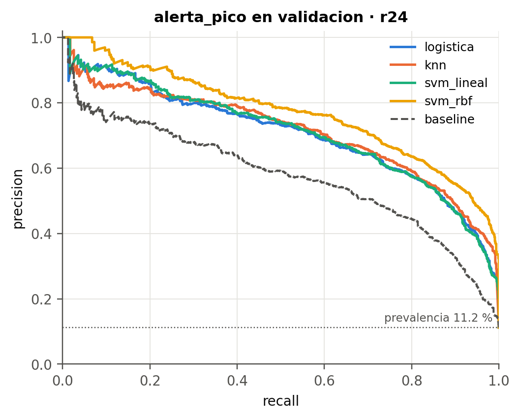

In [11]:
figura("precision_recall_r24.png", 520)

## 5. Ensembles: nivel frente a serie diferenciada

Un árbol no predice por encima del máximo que vio. Por eso cada ensemble se entrena sobre `demanda_mwh` y sobre `demanda_mwh − lag_168`.

In [12]:
ensembles = resultado("modelado_ensembles.json")
pd.DataFrame([{"tabla": clave, "modelo": nombre, "forma": forma, "MAPE %": r["metricas_validacion"]["mape_pct"],
               "sesgo MWh": r["metricas_validacion"]["sesgo_medio_mwh"],
               "pred > max": r["extrapolacion_validacion"]["predicciones_sobre_maximo"],
               "reales > max": r["extrapolacion_validacion"]["reales_sobre_maximo"],
               "ajuste s": r["tiempos"]["ajuste_s"]}
              for clave, t in ensembles["tablas"].items() for nombre, formas in t["modelos"].items()
              for forma, r in formas.items()]).round(2)

,tabla,modelo,forma,MAPE %,sesgo MWh,pred > max,reales > max,ajuste s
0,r24,random_forest,nivel,1.92,-34.33,0,3,3.07
1,r24,random_forest,diferenciado,2.18,-41.16,1,3,4.29
2,r24,adaboost,nivel,2.11,-52.90,0,3,8.39
3,r24,adaboost,diferenciado,2.31,-25.45,1,3,8.19
4,r24,gradient_boosting,nivel,1.87,-47.14,0,3,28.78
5,r24,gradient_boosting,diferenciado,1.99,-44.46,0,3,26.81
6,r24,hist_gradient,nivel,1.93,-49.44,0,3,0.83
7,r24,hist_gradient,diferenciado,2.05,-57.73,1,3,0.84
8,r120,random_forest,nivel,2.66,-93.84,0,3,2.42
9,r120,random_forest,diferenciado,2.82,-82.33,0,3,2.85


## 6. Búsqueda de hiperparámetros: Grid frente a Random

Se aplica a los 3 mejores de regresión y al mejor clasificador, con el mismo espacio y el mismo presupuesto en los dos métodos.

In [13]:
busqueda = resultado("modelado_busqueda.json")
pd.DataFrame([{"tabla": clave, "modelo": etiqueta, "metodo": metodo, "puntaje CV": r[metodo]["mejor_puntaje_cv"],
               "ajustes": r[metodo]["n_ajustes"], "segundos": r[metodo]["segundos_total"],
               "mejores": r[metodo]["mejores"],
               "random alcanza a grid": r["comparacion"]["random_alcanza_grid"] if metodo == "random" else None}
              for clave, t in busqueda["tablas"].items() for etiqueta, r in t["modelos"].items()
              for metodo in ("grid", "random")]).round(3)

,tabla,modelo,metodo,puntaje CV,ajustes,segundos,mejores,random alcanza a grid
0,r24,gradient_boosting (nivel),grid,-207.263,91,287.578,"{'learning_rate': 0.05, 'max_depth': 6, 'n_est...",None
1,r24,gradient_boosting (nivel),random,-207.790,91,254.004,"{'learning_rate': 0.053341537944799976, 'max_d...",True
2,r24,random_forest (nivel),grid,-184.807,91,139.757,"{'max_features': 0.8, 'max_samples': 1.0, 'min...",None
3,r24,random_forest (nivel),random,-189.973,91,100.119,"{'max_features': 0.7041986740582306, 'max_samp...",False
4,r24,hist_gradient (nivel),grid,-210.303,91,21.044,"{'l2_regularization': 1.0, 'learning_rate': 0....",None
5,r24,hist_gradient (nivel),random,-214.743,91,21.670,"{'l2_regularization': 0.6116531604882809, 'lea...",False
6,r24,svm_rbf,grid,0.629,101,5.562,"{'C': 30.0, 'gamma': 0.01}",None
7,r24,svm_rbf,random,0.639,101,5.182,"{'C': 13.867767003062493, 'gamma': 0.020589728...",True
8,r120,random_forest (nivel),grid,-257.197,91,105.631,"{'max_features': 0.8, 'max_samples': 0.5, 'min...",None
9,r120,random_forest (nivel),random,-258.321,91,99.782,"{'max_features': 0.7916154429033941, 'max_samp...",True


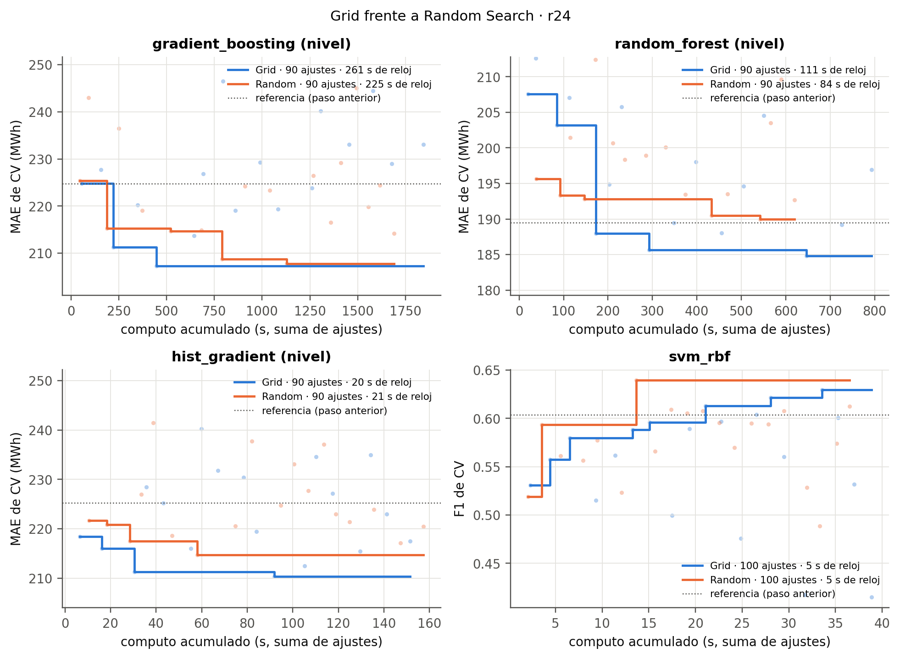

In [14]:
figura("busqueda_puntaje_tiempo_r24.png")

## 7. Interpretabilidad

Explica el mejor lineal y el mejor ensemble en validación. El contraste con el EDA: la autocorrelación a 168 h (0,924) es mayor que a 24 h, ¿domina `lag_168`?

In [15]:
interpretacion = resultado("modelado_interpretabilidad.json")
for clave, t in interpretacion["tablas"].items():
    print(clave, "->", t["contraste_eda"]["conclusion"])
pd.DataFrame(interpretacion["tablas"]["r24"]["contraste_eda"]["medidas"])

r24 -> lag_168 es la variable mas importante en 4 de 5 medidas; donde no lo es, la primera es lag_24.
r120 -> lag_168 es la variable mas importante en 5 de 5 medidas.


,modelo,medida,primera,tres_primeras,puesto_lag_168,puesto_lag_24,lag_168_antes_que_lag_24
0,ensemble,permutacion,lag_24,"[lag_24, lag_168, dia_semana_sin]",2,1,False
1,ensemble,impureza,lag_168,"[lag_168, lag_24, es_festivo]",1,2,True
2,ensemble,shap,lag_168,"[lag_168, lag_24, dia_semana_sin]",1,2,True
3,lineal,permutacion,lag_168,"[lag_168, lag_24, es_festivo]",1,2,True
4,lineal,shap,lag_168,"[lag_168, lag_24, temperatura_c]",1,2,True


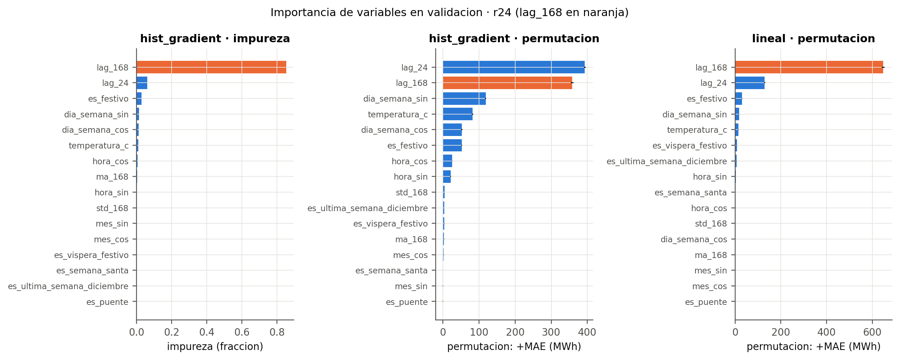

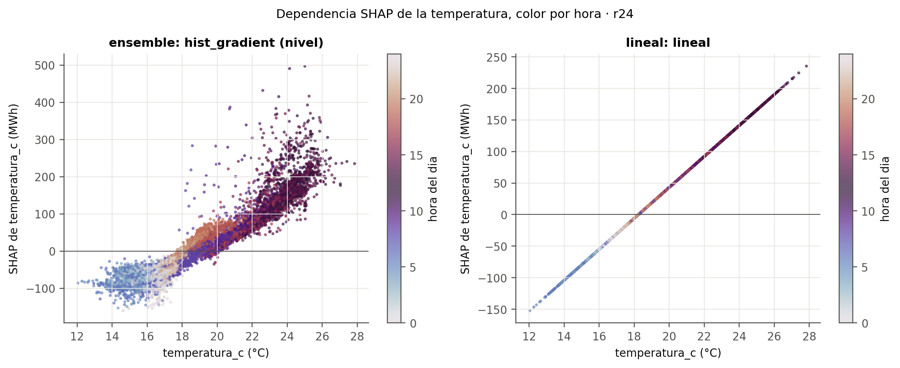

In [16]:
figura("importancias_r24.png")
figura("shap_temperatura_r24.png")

In [17]:
pd.DataFrame(interpretacion["tablas"]["r24"]["calificaciones"]).T

,calificacion,motivo
baseline_estacional,alta,"la prediccion es lag_168, sin parametros."
baseline_diario,alta,"la prediccion es lag_24, sin parametros."
lineal,alta,un coeficiente por variable; SHAP coincide con...
ridge,alta,"como la lineal, con coeficientes contraidos y ..."
lasso,alta,coeficientes por variable y ademas anula los i...
elasticnet,alta,coeficientes por variable con contraccion mixt...
polinomial,media,152 terminos con cuadrados e interacciones; ma...
polinomial_ridge,media,152 terminos con interacciones; Ridge los esta...
random_forest,baja,200 arboles profundos; se explica a posteriori...
adaboost,baja,100 arboles con mediana ponderada; TreeExplain...


## 8. Selección del modelo final (bloque de prueba)

`scripts/evaluar_final.py` reentrena con entrenamiento + validación y evalúa una vez en prueba. La elección se hizo con validación; la prueba solo confirma. La justificación completa está en `docs/modelado/seleccion.md`.

In [18]:
seleccion = resultado("modelado_seleccion.json")
pd.DataFrame([{"tabla": clave, "rol": f["rol"], "modelo": f["modelo"], "final": f["es_final"],
               "MAPE val %": f["rendimiento"]["validacion"].get("mape_pct"),
               "MAPE prueba %": f["rendimiento"]["prueba"].get("mape_pct"),
               "MAPE pico %": f["rendimiento"]["prueba"].get("mape_pico_pct"),
               "mejora %": f["rendimiento"]["prueba"].get("mejora_mape_pct"),
               "PR-AUC": f["rendimiento"]["prueba"].get("pr_auc"),
               "interpretabilidad": f["interpretabilidad"]["calificacion"],
               "prediccion ms/1000": f["eficiencia"]["prediccion_ms_por_1000_filas"],
               "MB": f["eficiencia"]["tamano_bytes"] / 1e6}
              for clave, t in seleccion["tablas"].items() for f in t["tabla_seleccion"]]).round(3)

,tabla,rol,modelo,final,MAPE val %,MAPE prueba %,MAPE pico %,mejora %,PR-AUC,interpretabilidad,prediccion ms/1000,MB
0,r24,baseline,baseline estacional (lag_168),False,3.350,3.541,3.124,NaN,NaN,alta,0.001,0.001
1,r24,lineal,polinomial_ridge,False,2.179,2.277,2.399,35.708,NaN,media,0.904,0.003
2,r24,ensemble,hist_gradient (nivel),True,1.864,2.205,2.871,37.732,NaN,baja,8.187,1.095
3,r24,clasificador,svm_rbf,False,NaN,NaN,NaN,NaN,0.800,baja,131.208,0.286
4,r120,baseline,baseline estacional (lag_168),False,3.350,3.541,3.124,NaN,NaN,alta,0.001,0.001
5,r120,lineal,polinomial_ridge,False,2.869,3.102,3.644,12.394,NaN,media,0.865,0.003
6,r120,ensemble,random_forest (nivel),True,2.657,3.281,3.833,7.351,NaN,baja,14.323,57.592
7,r120,clasificador,svm_rbf,False,NaN,NaN,NaN,NaN,0.709,baja,167.327,0.326


In [19]:
for clave, t in seleccion["tablas"].items():
    c = t["final"]["criterio_exito_prueba"]
    print(f"{clave}: {t['final']['etiqueta']} · mejora {c['mejora_mape_pct']:+.1f} % · pico {c['mape_pico_pct']:.2f} % "
          f"frente a {c['mape_pico_baseline_pct']:.2f} % -> {'CUMPLE' if c['cumple'] else 'NO cumple'} el criterio")
print("costo del rezago (modelo final):", {k: round(v, 2) for k, v in seleccion["costo_rezago"]["final"].items() if isinstance(v, float)})

r24: hist_gradient (nivel) · mejora +37.7 % · pico 2.87 % frente a 3.12 % -> CUMPLE el criterio
r120: random_forest (nivel) · mejora +7.4 % · pico 3.83 % frente a 3.12 % -> NO cumple el criterio
costo del rezago (modelo final): {'mape_r24_pct': 2.21, 'mape_r120_pct': 3.28, 'aumento_puntos': 1.08, 'aumento_relativo_pct': 48.79}


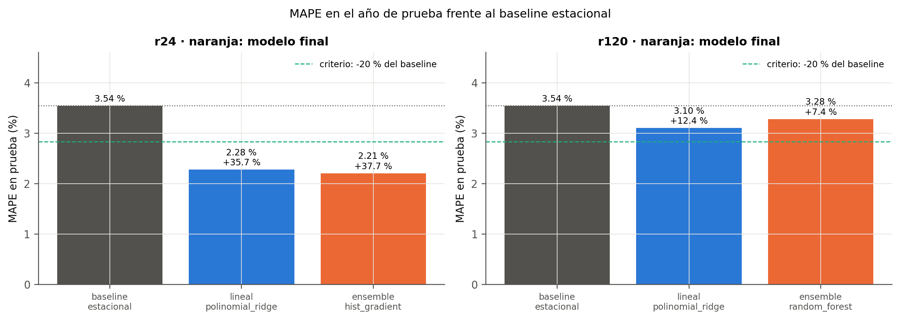

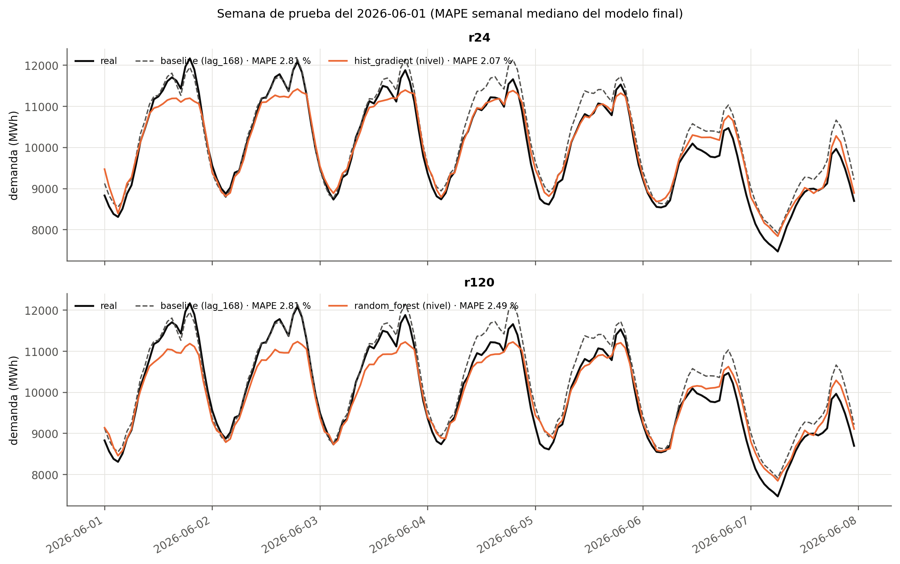

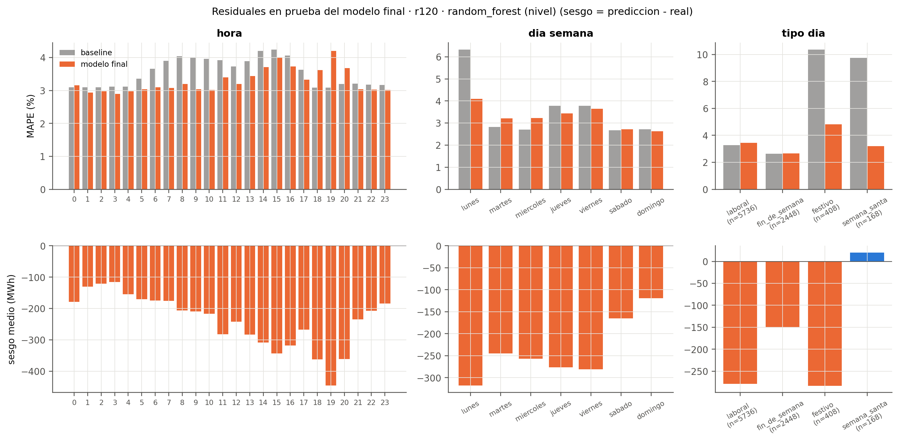

In [20]:
figura("mape_prueba.png")
figura("semana_prueba.png")
figura("residuales_r120.png")

El modelo final se carga de `models/` comprobando su SHA-256, como en `scripts/predecir.py`, y reproduce las predicciones evaluadas:

In [21]:
from modelado.tiempos import cargar_modelo

predicciones = pd.read_parquet(RESULTADOS / "predicciones_prueba.parquet")
for clave in ("r24", "r120"):
    final = seleccion["tablas"][clave]["final"]
    modelo = cargar_modelo(RAIZ / "models" / Path(final["modelo"]["ruta"]).name, final["modelo"]["sha256"])
    X, y, fechas = datos[clave]
    prueba = particiones[clave]["prueba"]
    nuevas = modelo.predict(X.iloc[prueba].astype("float64"))
    guardadas = predicciones.query("tabla == @clave and es_final")["prediccion_mwh"].to_numpy()
    print(clave, final["etiqueta"], "-> identicas a las evaluadas:", bool(abs(nuevas - guardadas).max() < 1e-6))

r24 hist_gradient (nivel) -> identicas a las evaluadas: True


r120 random_forest (nivel) -> identicas a las evaluadas: True
